In [1]:
import os
import h5py
import glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import quad
from astropy import constants as const
from scipy.interpolate import interp1d

In [2]:
k_B = 8.617333262e-5  # eV/K

def dL_ISM_de_shape(e): #, T_ISM):
    """
    Unnormalized spectral shape (dimensionless)
    """
    e = np.asarray(e)
    e0 = 240 # (eV) k_B * T_ISM

    return np.where(e < e0, 1.0, (e / e0) ** (-3.0))

In [3]:
dL_ISM_de_shape(24)

array(1.)

In [4]:
def L_ISM(SFR):
    """
    Total ISM luminosity between 13.6–2000 eV
    SFR in Msun / yr
    Output in erg / s
    """
    return 3.3e40 * SFR

In [5]:
def dL_ISM_de(e, SFR, T_ISM, e_min=13.6, e_max=2000.0):
    """
    Fully normalized ISM spectrum
    
    Returns dL/de in erg s^-1 eV^-1
    """
    # Energy grid for normalization
    e_grid = np.logspace(np.log10(e_min), np.log10(e_max), 5000)
    
    shape = dL_ISM_de_shape(e_grid)#, T_ISM)
    integral = np.trapz(shape, e_grid)

    # Normalization
    A = L_ISM(SFR) / integral

    return A * dL_ISM_de_shape(e, T_ISM)

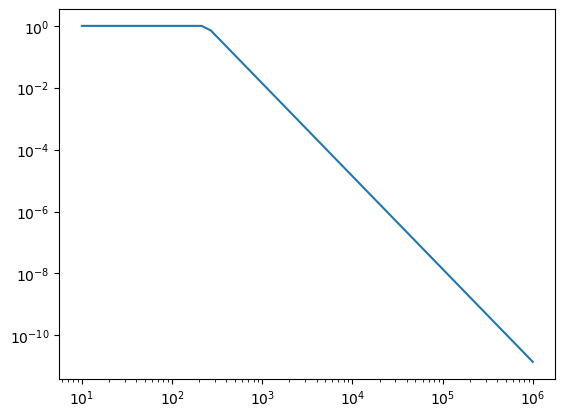

In [6]:
energy = np.logspace(1,6)
plt.loglog(energy, dL_ISM_de_shape(energy))

In [7]:
energy

array([1.00000000e+01, 1.26485522e+01, 1.59985872e+01, 2.02358965e+01,
       2.55954792e+01, 3.23745754e+01, 4.09491506e+01, 5.17947468e+01,
       6.55128557e+01, 8.28642773e+01, 1.04811313e+02, 1.32571137e+02,
       1.67683294e+02, 2.12095089e+02, 2.68269580e+02, 3.39322177e+02,
       4.29193426e+02, 5.42867544e+02, 6.86648845e+02, 8.68511374e+02,
       1.09854114e+03, 1.38949549e+03, 1.75751062e+03, 2.22299648e+03,
       2.81176870e+03, 3.55648031e+03, 4.49843267e+03, 5.68986603e+03,
       7.19685673e+03, 9.10298178e+03, 1.15139540e+04, 1.45634848e+04,
       1.84206997e+04, 2.32995181e+04, 2.94705170e+04, 3.72759372e+04,
       4.71486636e+04, 5.96362332e+04, 7.54312006e+04, 9.54095476e+04,
       1.20679264e+05, 1.52641797e+05, 1.93069773e+05, 2.44205309e+05,
       3.08884360e+05, 3.90693994e+05, 4.94171336e+05, 6.25055193e+05,
       7.90604321e+05, 1.00000000e+06])

In [8]:
import numpy as np

# Polynomial coefficients β0 ... β8
beta = np.array([
    4.0431737e+01,   # β0
    1.3511736e+02,   # β1
   -1.0627360e+05,   # β2
    2.5606802e+07,   # β3
   -3.0811049e+09,   # β4
    2.0496541e+11,   # β5
   -7.6798616e+12,   # β6
    1.5199552e+14,   # β7
   -1.2367941e+15    # β8
])

def log_LHMXB_per_SFR(Z):
    """
    Returns log10(L_HMXB / SFR) as a function of metallicity Z
    Z can be scalar or NumPy array
    """
    Z = np.asarray(Z)
    powers = np.array([Z**i for i in range(len(beta))])
    return np.sum(beta[:, None] * powers, axis=0)

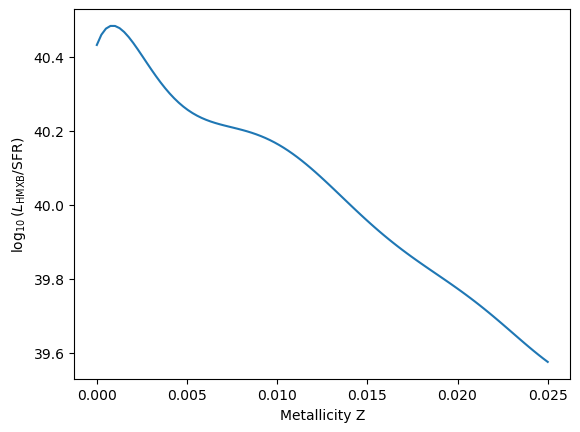

In [9]:
Z = np.linspace(0.0, 0.025, 100)
logL = log_LHMXB_per_SFR(Z)

import matplotlib.pyplot as plt
plt.plot(Z, logL)
plt.xlabel("Metallicity Z")
plt.ylabel(r"$\log_{10}(L_{\rm HMXB}/{\rm SFR})$")
plt.show()

In [10]:
def L_ISM(z):
    return 3.3e40 * SFRD(z) * YR / M_SOL

def L_HMXB(z, Z):
    """
    HMXB luminosity density.
    
    Parameters
    ----------
    z : scalar or array
        Redshift(s)
    Z : scalar or array
        Metallicity
    
    Returns
    -------
    L_HMXB : array
        Luminosity density in erg / s / cm^3
    """

    # Polynomial coefficients β0 ... β8
    beta = np.array([
        4.0431737e+01,   # β0
        1.3511736e+02,   # β1
       -1.0627360e+05,   # β2
        2.5606802e+07,   # β3
       -3.0811049e+09,   # β4
        2.0496541e+11,   # β5
       -7.6798616e+12,   # β6
        1.5199552e+14,   # β7
       -1.2367941e+15    # β8
    ])

    Z = np.asarray(Z)

    # polynomial in Z
    logL_per_SFR = np.zeros_like(Z, dtype=float)
    for i, b in enumerate(beta):
        logL_per_SFR += b * Z**i

    # convert to luminosity
    return 10.0**(logL_per_SFR)*SFRD(z)* YR / M_SOL 

def epsilon_X_alpha(z):
    Z = 1.0e-4
    return L_ISM(z) + L_HMXB(z, Z)


In [11]:
NU_LYMAN_ALPHA = 2.466e15      # Hz
PLANCK         = 6.62607015e-27
C_LIGHT        = 2.998e10

def x_e_of_z(z):
    return np.interp(z, df["redshift"], df["f_HII"])   # your ionized fraction

def f_alpha_X(x_e):
    # Fraction of deposited X-ray energy -> Ly-alpha excitation.
    # Shull & van Steenberg (1985) / Furlanetto & Stoever (2010).
    # Neutral limit ~0.4, declines with x_e. VERIFY coefficients vs source.
    x = np.clip(x_e, 1e-4, 1.0)
    return 0.48 * (1.0 - x**0.27)**1.52

def epsilon_X(z):                       # comoving X-ray ENERGY emissivity [erg/s/cm^3]
    Z = 1.0e-4
    return L_ISM(z) + L_HMXB(z, Z)

def J_alpha_X(z):                       # [ph/s/cm^2/Hz/sr]
    eps_alpha_proper = f_alpha_X(x_e_of_z(z)) * epsilon_X(z) * (1.0+z)**3 / (PLANCK*NU_LYMAN_ALPHA)
    return (C_LIGHT/(4.0*np.pi)) * eps_alpha_proper / (H_cgm(z) * NU_LYMAN_ALPHA)

In [12]:
J_alpha_X(3)

NameError: name 'df' is not defined